# 02 — Lieux, annotation et comparaison géographique

**Objectif :** relier les discours à leur lieu, sans confondre ce lieu avec les pays mentionnés ou l'origine du public.
Les propositions ci-dessous sont des règles transparentes adaptées au pilote, pas un géocodage validé. Les inconnus sont conservés.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "telecharger_discours.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dossier du projet.")
CORPUS = ROOT / "corpus_francois" / "corpus_nlp.jsonl"
if not CORPUS.exists():
    raise FileNotFoundError("Exécuter telecharger_discours.py puis preparer_corpus.py ; voir README.")
LANGUE = "fr"
df_all = pd.read_json(CORPUS, lines=True)
df = df_all.loc[df_all["language"].eq(LANGUE)].copy()
if df.empty:
    raise ValueError(f"Aucun document en {LANGUE}.")
if df.duplicated(["event_id", "language"]).any():
    raise ValueError("Doublons événement/langue : examiner le corpus avant l'analyse.")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["text"] = df["text"].fillna("")
df["venue_raw"] = df["venue_raw"].fillna("")
df["n_mots"] = df["text"].str.findall(r"\b[^\W\d_]+(?:[’'-][^\W\d_]+)*\b").str.len()
RESULTATS = ROOT / "resultats"
RESULTATS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 14})
print(f"{len(df)} versions {LANGUE} ; {df['event_id'].nunique()} documents distincts.")
print("Période :", df["date"].min(), "→", df["date"].max())


33 versions fr ; 33 documents distincts.
Période : 2015-09-03 00:00:00 → 2015-09-27 00:00:00


In [2]:
# Suggestions de ville à partir du seul lieu d'en-tête : aucune recherche dans le corps.
def proposer_ville(venue):
    v = venue.casefold()
    for motif, ville in [("new york", "New York"), ("washington", "Washington"),
                          ("philadelphie", "Philadelphie"), ("santiago de cuba", "Santiago de Cuba"),
                          ("havane", "La Havane")]:
        if motif in v:
            return ville
    if any(m in v for m in ["salle paul vi", "salle clémentine", "salle du consistoire", "salle des papes"]):
        return "Vatican (à vérifier)"
    return "Inconnu"

df["ville_suggeree"] = df["venue_raw"].map(proposer_ville)
ANNOTATIONS = ROOT / "annotations_lieux.csv"
if ANNOTATIONS.exists():
    annotations = pd.read_csv(ANNOTATIONS, keep_default_na=False)
    required = {"event_id", "language", "ville_validee", "pays_iso3", "statut"}
    if not required.issubset(annotations):
        raise ValueError(f"Colonnes d'annotation requises : {sorted(required)}")
    df = df.merge(annotations[list(required)], on=["event_id", "language"],
                  how="left", validate="one_to_one")
else:
    df["ville_validee"] = ""
    df["pays_iso3"] = ""
    df["statut"] = ""
df["lieu_analyse"] = np.where(
    df["statut"].eq("valide") & df["ville_validee"].fillna("").ne(""),
    df["ville_validee"], df["ville_suggeree"]
)


## Examiner les preuves

Le libellé vient de l'en-tête. Le statut `candidate_to_review` n'atteste pas que le lieu est vérifié. Les textes remis par écrit ou en avion nécessitent un traitement particulier.

In [3]:
display(df[["date", "title", "venue_raw", "ville_suggeree",
            "venue_evidence", "source_url"]].sort_values("date"))
display(df.loc[df["ville_suggeree"].eq("Inconnu"),
               ["date", "title", "header", "source_url"]])

,date,title,venue_raw,ville_suggeree,venue_evidence,source_url
0,2015-09-03,Aux participants au chapitre général des prêtr...,Salle du Consistoire,Vatican (à vérifier),Salle du Consistoire Jeudi 3 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
1,2015-09-05,Aux membres des cellules paroissiales d'évangé...,Salle Paul VI,Vatican (à vérifier),Salle Paul VI Samedi 5 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
2,2015-09-07,Aux prélats de la Conférence épiscopale du Por...,Salle Clémentine,Vatican (à vérifier),Salle Clémentine Lundi 7 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
3,2015-09-10,Aux participants à la rencontre organisée par ...,Salle Clémentine,Vatican (à vérifier),Salle Clémentine Jeudi 10 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
4,2015-09-10,Aux nouveaux évêques nommés au cours de l'anné...,Salle Clémentine,Vatican (à vérifier),Salle Clémentine Jeudi 10 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
5,2015-09-11,Aux participants à la rencontre organisée par ...,Salle Clémentine,Vatican (à vérifier),Salle Clémentine Vendredi 11 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
6,2015-09-11,Aux participants au Chapitre général des Missi...,Salle du Consistoire,Vatican (à vérifier),Salle du Consistoire Vendredi 11 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
7,2015-09-12,À la Banque de Crédit Coopératif de Rome (12 s...,Salle Paul VI,Vatican (à vérifier),Salle Paul VI Samedi 12 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...
8,2015-09-16,Aux ministres de l'environnement des États mem...,Salon adjacent à la salle Paul VI,Vatican (à vérifier),Salon adjacent à la salle Paul VI Mercredi 16 ...,https://www.vatican.va/content/francesco/fr/sp...
9,2015-09-17,Aux participants à la rencontre sur la crise h...,Salle du Consistoire,Vatican (à vérifier),Salle du Consistoire Jeudi 17 septembre 2015,https://www.vatican.va/content/francesco/fr/sp...


,date,title,header,source_url
14,2015-09-19,"Voyage apostolique à Cuba, aux États-Unis et à...","VOYAGE APOSTOLIQUE DU PAPE FRANÇOIS À CUBA, AU...",https://www.vatican.va/content/francesco/fr/sp...
17,2015-09-22,"Voyage apostolique à Cuba, aux États-Unis et à...","VOYAGE APOSTOLIQUE DU PAPE FRANÇOIS À CUBA, AU...",https://www.vatican.va/content/francesco/fr/sp...
29,2015-09-27,"Voyage apostolique à Cuba, aux États-Unis et à...","VOYAGE APOSTOLIQUE DU PAPE FRANÇOIS À CUBA, AU...",https://www.vatican.va/content/francesco/fr/sp...


## Préparer une annotation manuelle durable

Cette cellule crée `annotations_lieux.csv` uniquement s'il n'existe pas, puis ajoute seulement les nouveaux documents. Compléter `ville_validee`, `pays_iso3`, `statut` et `commentaire`. Utiliser exactement `valide` pour activer une correction. Les sources collectées ne sont pas modifiées. Les suggestions Vatican demandent une vérification ; les trajets en avion peuvent rester `Inconnu` avec un commentaire.

In [4]:
modele = df[["event_id", "language", "date", "title", "venue_raw", "venue_evidence", "source_url"]].copy()
for colonne in ["ville_validee", "pays_iso3", "statut", "commentaire"]:
    modele[colonne] = ""
if ANNOTATIONS.exists():
    existant = pd.read_csv(ANNOTATIONS, keep_default_na=False)
    keys = ["event_id", "language"]
    if existant.duplicated(keys).any():
        raise ValueError("Doublons dans annotations_lieux.csv ; corriger avant de poursuivre.")
    nouveaux = modele.merge(existant[keys], on=keys, how="left", indicator=True)
    nouveaux = nouveaux.loc[nouveaux["_merge"].eq("left_only")].drop(columns="_merge")
    if len(nouveaux):
        pd.concat([existant, nouveaux], ignore_index=True).to_csv(ANNOTATIONS, index=False, encoding="utf-8-sig")
        print(f"{len(nouveaux)} lignes ajoutées ; annotations existantes conservées.")
    else:
        print("Fichier existant conservé.")
else:
    modele.to_csv(ANNOTATIONS, index=False, encoding="utf-8-sig")
    print("Modèle créé :", ANNOTATIONS)
print("Après modification du CSV, réexécuter le notebook depuis le début.")

Modèle créé : C:\Users\arthr\Desktop\ENSAE 2A\S1\projet-discours\annotations_lieux.csv
Après modification du CSV, réexécuter le notebook depuis le début.


## Volumes et longueurs par lieu

Les graphiques combinent annotations validées et suggestions lorsqu'aucune validation n'existe. Ce sont des descriptions du corpus collecté ; une ville avec davantage de textes n'est pas forcément plus importante dans le pontificat.

,documents,mots_medians,mots_totaux,dates_distinctes
lieu_analyse,,,,
Santiago de Cuba,1,2119.0,2119,1
La Havane,2,1894.5,3789,2
Inconnu,3,2074.0,6190,3
New York,4,902.5,6080,1
Washington,4,2339.0,8991,2
Philadelphie,6,1396.5,9020,2
Vatican (à vérifier),13,1079.0,17274,9


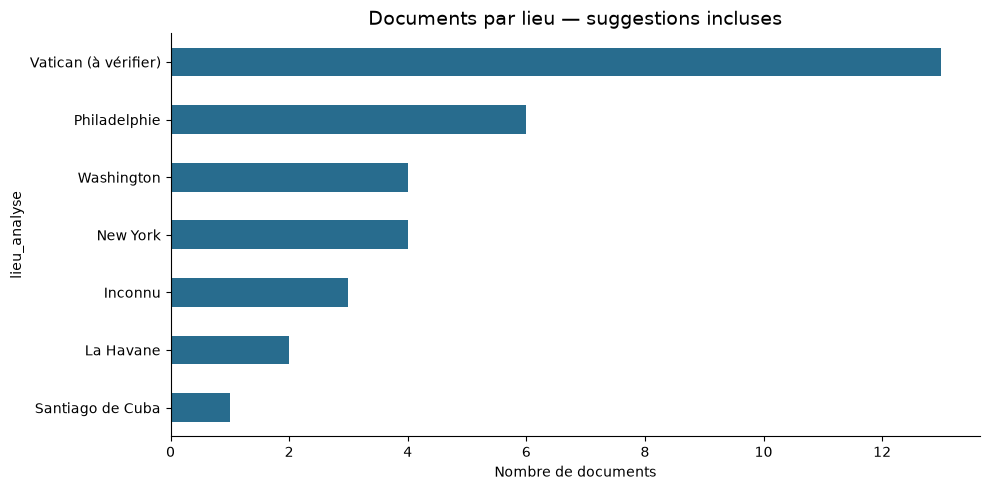

Annotations validées utilisées : 0


In [5]:
bilan = df.groupby("lieu_analyse").agg(
    documents=("event_id", "size"), mots_medians=("n_mots", "median"),
    mots_totaux=("n_mots", "sum"), dates_distinctes=("date", "nunique")
).sort_values("documents")
display(bilan)
bilan["documents"].plot.barh(color="#286c8e", title="Documents par lieu — suggestions incluses")
plt.xlabel("Nombre de documents")
plt.tight_layout()
plt.savefig(RESULTATS / "documents_par_lieu.png", dpi=160, bbox_inches="tight")
plt.show()
bilan.to_csv(RESULTATS / "bilan_lieux.csv", encoding="utf-8-sig")
print("Annotations validées utilisées :", (df["statut"].eq("valide") & df["ville_validee"].fillna("").ne("")).sum())

## Calendrier des lieux

Ce calendrier permet de voir le lien entre déplacement et période. Lieu et temps peuvent être confondus : une différence de vocabulaire ne prouve pas un effet causal du lieu.

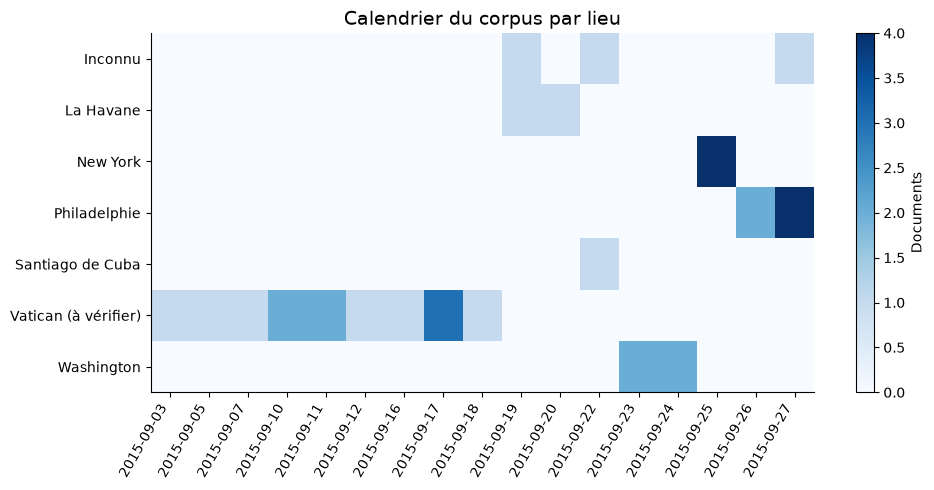

In [6]:
calendrier = pd.crosstab(df["lieu_analyse"], df["date"].dt.strftime("%Y-%m-%d"))
if not calendrier.empty:
    fig, ax = plt.subplots(figsize=(max(10, min(20, calendrier.shape[1] * .45)), 5))
    im = ax.imshow(calendrier, aspect="auto", cmap="Blues")
    ax.set_yticks(range(len(calendrier)), calendrier.index)
    # Limiter le nombre d'étiquettes quand le corpus couvre plusieurs années.
    step = max(1, len(calendrier.columns) // 24)
    ticks = list(range(0, len(calendrier.columns), step))
    ax.set_xticks(ticks, calendrier.columns[ticks], rotation=60, ha="right")
    fig.colorbar(im, ax=ax, label="Documents")
    ax.set_title("Calendrier du corpus par lieu")
    fig.tight_layout()
    plt.show()
else:
    print("Aucune date exploitable.")

## Extension

Pour une carte, ajouter des coordonnées issues d'un référentiel identifié après validation des villes. Pour les lieux mentionnés, créer une table distincte d'entités du corps du texte. Ne pas utiliser ces mentions pour remplir le lieu d'énonciation.